# Planar aperture: vector far field and backend agreement

This notebook projects a prescribed, finite Gaussian aperture in free space. Its sampled E/H fields are controlled inputs, not a full-wave solution. We inspect aperture components, the complex vector radiation pattern, and the far-field intensity proxy on a direction-cosine grid. The direct Torch projector is compared with its separable planar implementation on the same angular samples; this checks backend agreement, not the physical accuracy of the finite-aperture model.

Coordinates are in meters internally. Input/output aperture fields are V/m and A/m. `project_farfield` returns coefficients in V and A because the common `exp(ikr)/r` factor is omitted. `directional_power` gives radiation intensity in W/sr. The plotted `|E|²` is a convenient field-intensity proxy; it is not a flux or power measurement.

In [ ]:
# Locate the repository from the notebook directory or a parent working directory.
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
notebook_dir = next(
    (p for p in (cwd, *cwd.parents) if (p / "examples/nearfield").is_dir()), None
)
if notebook_dir is None and (cwd / "01_planar_farfield.ipynb").exists():
    notebook_dir = cwd
repo_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "core/nearfield").is_dir()), None
)
if repo_root is None:
    repo_root = next(
        (p.parent for p in cwd.parents if (p / "core/nearfield").is_dir()), None
    )
if repo_root is None:
    raise RuntimeError("Could not locate the MAPS repository root")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
if str(repo_root / "examples/nearfield") not in sys.path:
    sys.path.insert(0, str(repo_root / "examples/nearfield"))

import math
import torch
import matplotlib.pyplot as plt
from core.nearfield import make_planar_surface, project_farfield, directional_power, C_0
from core.nearfield.accelerated import project_farfield_separable
from notebook_utils import (
    field_components,
    field_comparison,
    error_summary,
    show_errors,
    benchmark_methods,
    show_benchmarks,
    surface_copy,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
REAL = torch.float64
COMPLEX = torch.complex128
FREQUENCY_HZ = torch.tensor([193.4e12], dtype=REAL, device=DEVICE)
WAVELENGTH_M = C_0 / FREQUENCY_HZ[0]
print(f"device={DEVICE}; dtype={COMPLEX}; wavelength={WAVELENGTH_M.item()*1e6:.4f} µm")

device=cuda; dtype=torch.complex128; wavelength=1.5501 µm


In [ ]:
# Prescribed finite aperture, with the magnetic field consistent with a +z traveling wave.
source_n = 25 if DEVICE.type == "cuda" else 17
aperture_half_width_m = 2.0e-6
axis_m = torch.linspace(
    -aperture_half_width_m, aperture_half_width_m, source_n, dtype=REAL, device=DEVICE
)
y_m, x_m = torch.meshgrid(axis_m, axis_m, indexing="ij")
aperture = torch.exp(-((x_m / 1.2e-6) ** 2 + (y_m / 0.8e-6) ** 2)).to(COMPLEX)
impedance_0 = 376.730313668
E_aperture = torch.zeros((1, source_n, source_n, 3), dtype=COMPLEX, device=DEVICE)
H_aperture = torch.zeros_like(E_aperture)
E_aperture[0, ..., 0] = aperture
H_aperture[0, ..., 1] = aperture / impedance_0
surface = make_planar_surface(
    origin_m=torch.zeros(3, dtype=REAL, device=DEVICE),
    u_axis=torch.tensor([1.0, 0.0, 0.0], dtype=REAL, device=DEVICE),
    v_axis=torch.tensor([0.0, 1.0, 0.0], dtype=REAL, device=DEVICE),
    u_coordinates_m=axis_m,
    v_coordinates_m=axis_m,
    electric_fields=E_aperture,
    magnetic_fields=H_aperture,
    frequencies_hz=FREQUENCY_HZ,
)

# Use a tensor-product direction-cosine grid fully inside the propagating disk.
angle_n = 31 if DEVICE.type == "cuda" else 19
u_axis = torch.linspace(-0.68, 0.68, angle_n, dtype=REAL, device=DEVICE)
v_axis = torch.linspace(-0.68, 0.68, angle_n, dtype=REAL, device=DEVICE)
vv, uu = torch.meshgrid(v_axis, u_axis, indexing="ij")
limit = 0.68 / math.sqrt(2.0)
u_axis = torch.linspace(-limit, limit, angle_n, dtype=REAL, device=DEVICE)
v_axis = torch.linspace(-limit, limit, angle_n, dtype=REAL, device=DEVICE)
vv, uu = torch.meshgrid(v_axis, u_axis, indexing="ij")
uz = torch.sqrt(1.0 - uu.square() - vv.square())
directions = torch.stack((uu, vv, uz), dim=-1)

E_direct, H_direct = project_farfield(surface, directions.reshape(-1, 3))
E_separable_grid, H_separable_grid = project_farfield_separable(
    surface,
    u_axis=torch.tensor([1.0, 0.0, 0.0], dtype=REAL, device=DEVICE),
    v_axis=torch.tensor([0.0, 1.0, 0.0], dtype=REAL, device=DEVICE),
    u_coordinates_m=axis_m,
    v_coordinates_m=axis_m,
    u_directions=u_axis,
    v_directions=v_axis,
    origin_m=torch.zeros(3, dtype=REAL, device=DEVICE),
)
E_separable = E_separable_grid.reshape_as(E_direct)
H_separable = H_separable_grid.reshape_as(H_direct)
print(
    f"source samples={source_n**2}; angular directions={angle_n**2}; direction cosine extent={limit:.3f}"
)

source samples=625; angular directions=961; direction cosine extent=0.481


In [ ]:
# A separate leaf copy lets us compare field gradients without altering the input sample tensors.
grad_surface_direct = surface_copy(surface, requires_grad=True)
E_grad_direct, H_grad_direct = project_farfield(
    grad_surface_direct, directions.reshape(-1, 3)
)
loss_direct = E_grad_direct.abs().square().sum() + H_grad_direct.abs().square().sum()
grad_direct = torch.autograd.grad(
    loss_direct,
    (grad_surface_direct.electric_fields, grad_surface_direct.magnetic_fields),
)

grad_surface_sep = surface_copy(surface, requires_grad=True)
E_grad_sep, H_grad_sep = project_farfield_separable(
    grad_surface_sep,
    u_axis=torch.tensor([1.0, 0.0, 0.0], dtype=REAL, device=DEVICE),
    v_axis=torch.tensor([0.0, 1.0, 0.0], dtype=REAL, device=DEVICE),
    u_coordinates_m=axis_m,
    v_coordinates_m=axis_m,
    u_directions=u_axis,
    v_directions=v_axis,
    origin_m=torch.zeros(3, dtype=REAL, device=DEVICE),
)
loss_sep = E_grad_sep.abs().square().sum() + H_grad_sep.abs().square().sum()
grad_sep = torch.autograd.grad(
    loss_sep, (grad_surface_sep.electric_fields, grad_surface_sep.magnetic_fields)
)

grad_error = torch.sqrt(
    sum((a - b).abs().square().sum() for a, b in zip(grad_direct, grad_sep))
)
grad_scale = torch.sqrt(sum(a.abs().square().sum() for a in grad_direct)).clamp_min(
    torch.finfo(REAL).tiny
)
print(
    f"relative complex E/H far-field error: {((E_direct-E_separable).norm()**2 + (H_direct-H_separable).norm()**2).sqrt().item() / ((E_direct.norm()**2 + H_direct.norm()**2).sqrt().item() + 1e-300):.3e}"
)
print(f"relative input-gradient difference: {(grad_error/grad_scale).item():.3e}")

relative complex E/H far-field error: 2.677e-16
relative input-gradient difference: 4.474e-16


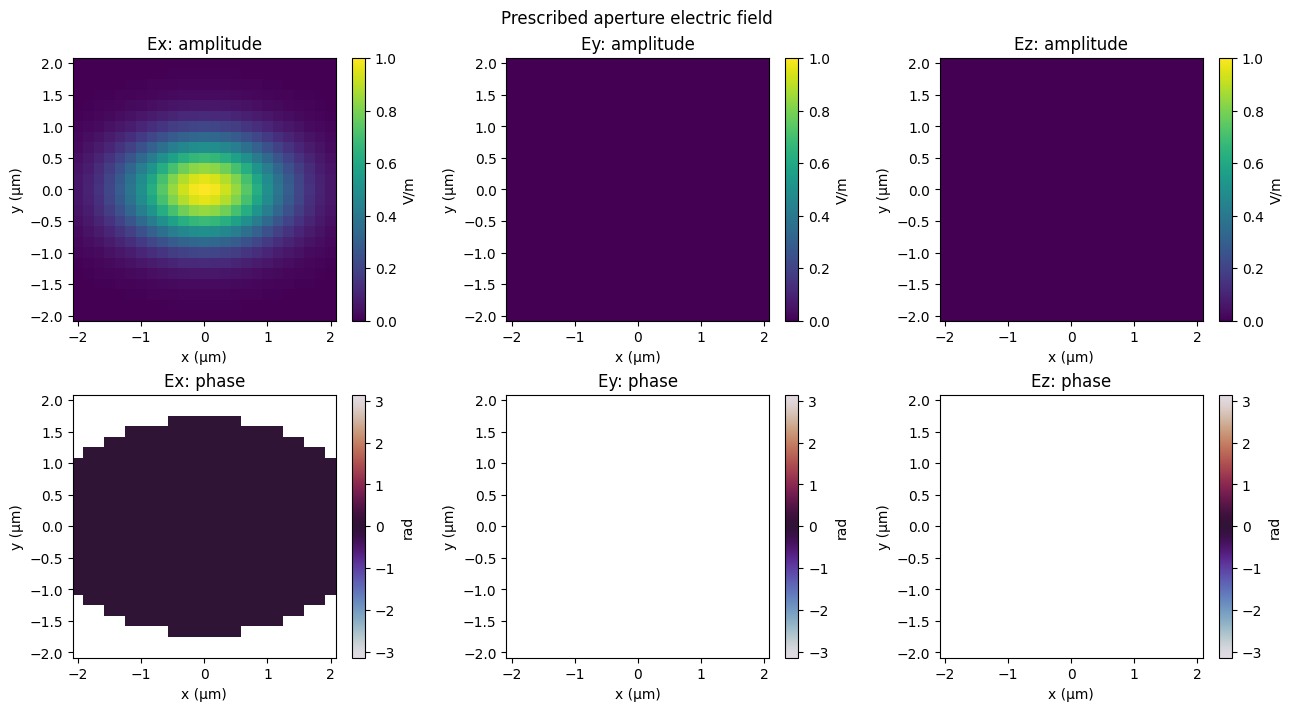

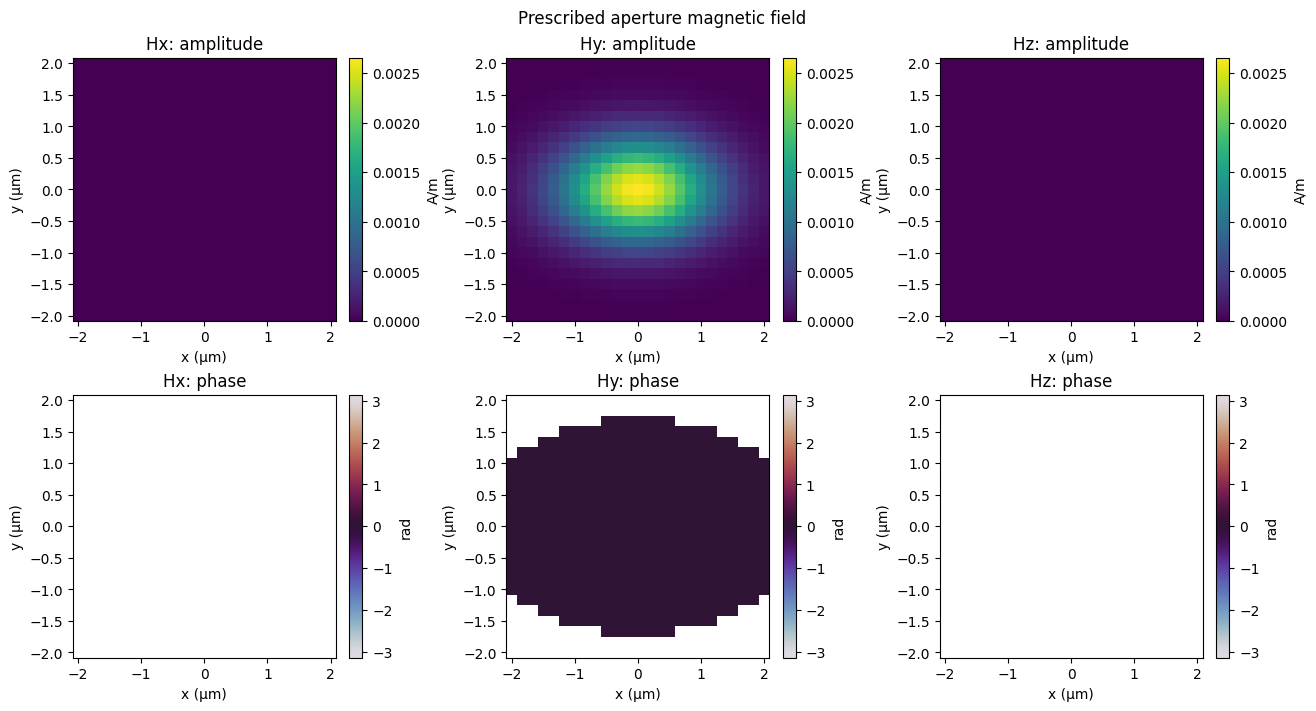

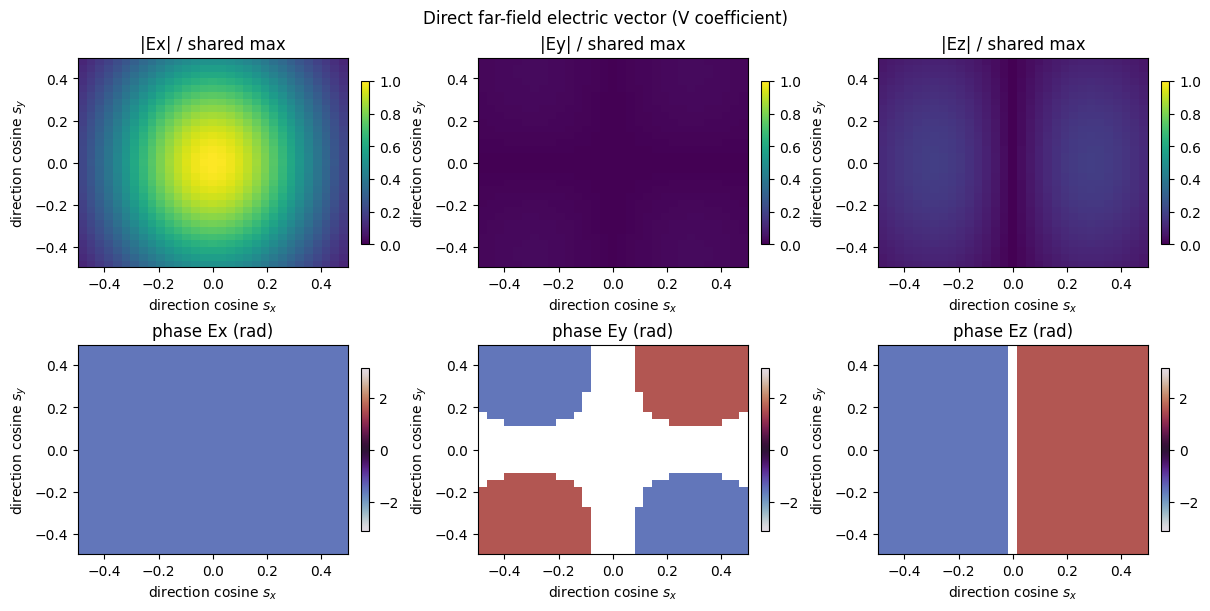

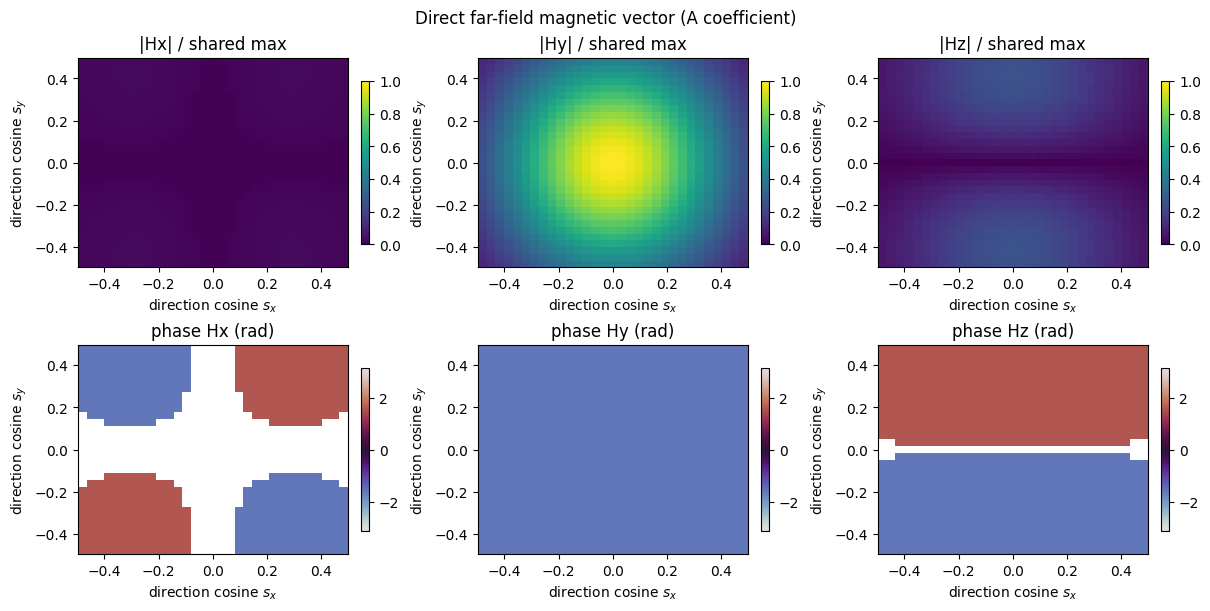

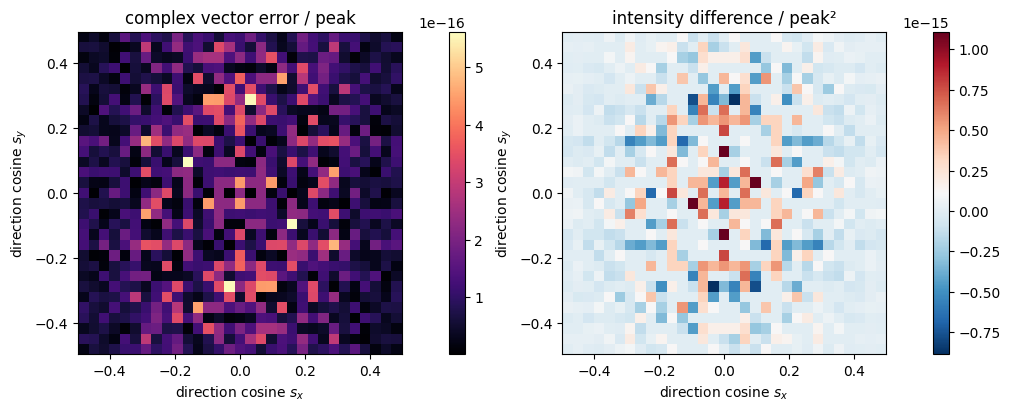

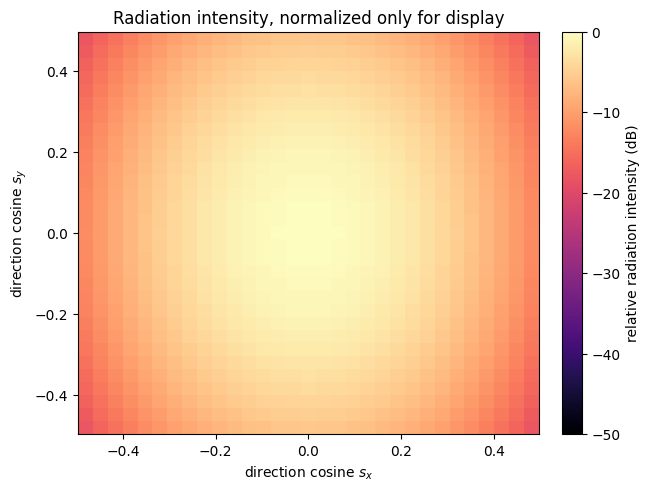

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
direct vs separable E,2.6771e-16,2.5595e-16,1.2419e-16,2.6771e-16,N/A,961,0
direct vs separable H,2.725e-16,2.6095e-16,1.3579e-16,2.725e-16,N/A,961,0


method,device,dtype,output_shape,first_forward_ms,warm_forward_ms,first_gradient_forward_ms,first_backward_ms,warm_backward_ms,warm_forward_backward_ms,peak_allocated_mib,peak_increment_mib,warmups,repeats
direct Torch,cuda,torch.complex128,"(1, 961, 3)",23.8,21.429,20.564,11.97,11.832,32.792,21.547,4.3716,1,3
separable Torch,cuda,torch.complex128,"(1, 31, 31, 3)",2.1859,1.8748,2.0148,0.9097,0.87783,2.8548,17.775,0.6001,1,3


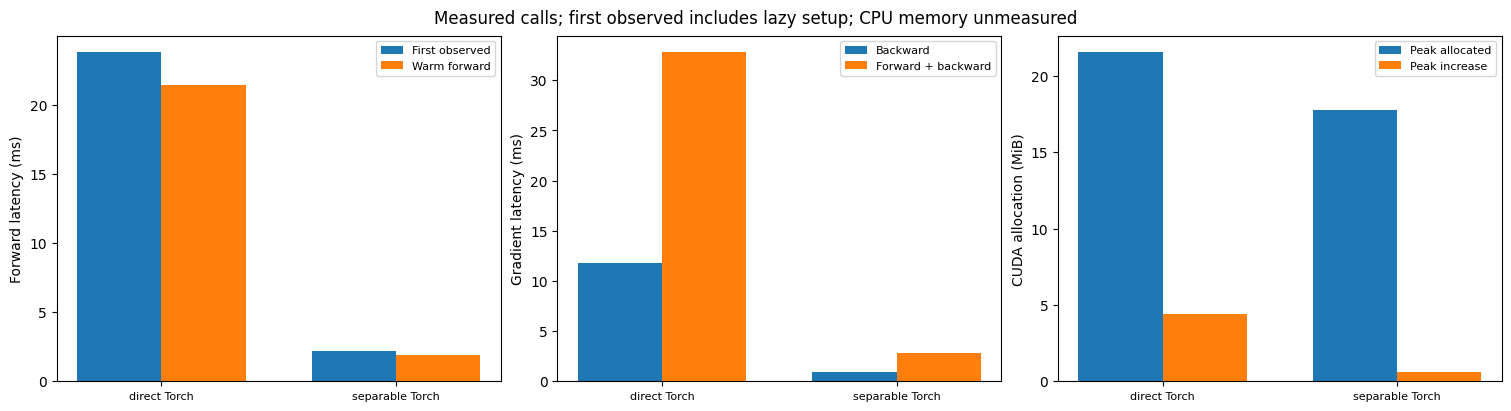

In [ ]:
# Component maps use micrometers for axes; the shared scale makes component amplitudes comparable.
_ = field_components(
    E_aperture[0],
    axis_m.detach().cpu().numpy() * 1e6,
    axis_m.detach().cpu().numpy() * 1e6,
    title="Prescribed aperture electric field",
    quantity="E",
    units="V/m",
)
_ = field_components(
    H_aperture[0],
    axis_m.detach().cpu().numpy() * 1e6,
    axis_m.detach().cpu().numpy() * 1e6,
    title="Prescribed aperture magnetic field",
    quantity="H",
    units="A/m",
)


# Angular E/H component maps preserve complex phase and use dimensionless direction-cosine axes.
def plot_angular_components(field_grid, title, units, quantity):
    values = field_grid[0]
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
    peak = values.abs().max().clamp_min(torch.finfo(REAL).tiny)
    for comp, name in enumerate(("x", "y", "z")):
        value = values[..., comp]
        amp = value.abs() / peak
        phase = torch.angle(value).masked_fill(value.abs() < 0.01 * peak, float("nan"))
        for row, (data, cmap, limits, label) in enumerate(
            (
                (amp, "viridis", (0, 1), f"|{quantity}{name}| / shared max"),
                (
                    phase,
                    "twilight",
                    (-math.pi, math.pi),
                    f"phase {quantity}{name} (rad)",
                ),
            )
        ):
            mesh = axes[row, comp].pcolormesh(
                u_axis.cpu(),
                v_axis.cpu(),
                data.detach().cpu(),
                shading="auto",
                cmap=cmap,
                vmin=limits[0],
                vmax=limits[1],
            )
            axes[row, comp].set(
                xlabel=r"direction cosine $s_x$",
                ylabel=r"direction cosine $s_y$",
                title=label,
            )
            fig.colorbar(mesh, ax=axes[row, comp], shrink=0.78)
    fig.suptitle(title + f" ({units} coefficient)")
    plt.show()
    return fig


plot_angular_components(
    E_direct.reshape(1, angle_n, angle_n, 3),
    "Direct far-field electric vector",
    "V",
    "E",
)
plot_angular_components(
    H_direct.reshape(1, angle_n, angle_n, 3),
    "Direct far-field magnetic vector",
    "A",
    "H",
)

# Local angular difference maps complement the complex norm and gradient tables.
E_ref = E_direct.reshape(angle_n, angle_n, 3)
E_alt = E_separable_grid[0]
E_peak = E_ref.abs().max().clamp_min(torch.finfo(REAL).tiny)
I_ref, I_alt = E_ref.abs().square().sum(-1), E_alt.abs().square().sum(-1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, data, title, cmap in (
    (
        axes[0],
        (torch.linalg.vector_norm(E_alt - E_ref, dim=-1) / E_peak),
        "complex vector error / peak",
        "magma",
    ),
    (
        axes[1],
        (I_alt - I_ref) / E_peak.square(),
        "intensity difference / peak²",
        "RdBu_r",
    ),
):
    mesh = ax.pcolormesh(
        u_axis.cpu(), v_axis.cpu(), data.detach().cpu(), shading="auto", cmap=cmap
    )
    ax.set(
        xlabel=r"direction cosine $s_x$", ylabel=r"direction cosine $s_y$", title=title
    )
    fig.colorbar(mesh, ax=ax)
plt.show()

intensity = directional_power(E_direct)[0].reshape(angle_n, angle_n)
relative_db = 10.0 * torch.log10(
    (intensity / intensity.max().clamp_min(torch.finfo(REAL).tiny)).clamp_min(1e-12)
)
fig, ax = plt.subplots(figsize=(6.4, 4.8), constrained_layout=True)
image = ax.pcolormesh(
    u_axis.cpu().numpy(),
    v_axis.cpu().numpy(),
    relative_db.detach().cpu().numpy(),
    shading="auto",
    cmap="magma",
    vmin=-50,
    vmax=0,
)
ax.set(
    xlabel=r"direction cosine $s_x$",
    ylabel=r"direction cosine $s_y$",
    title="Radiation intensity, normalized only for display",
)
fig.colorbar(image, ax=ax, label="relative radiation intensity (dB)")
plt.show()
show_errors(
    [
        error_summary(E_direct, E_separable, label="direct vs separable E"),
        error_summary(H_direct, H_separable, label="direct vs separable H"),
    ]
)

# Timings are measured in the current runtime; this includes warm-up and repeated forward/backward work.
bench_surface = surface_copy(surface, requires_grad=True)
bench_methods = {
    "direct Torch": lambda: project_farfield(bench_surface, directions.reshape(-1, 3)),
    "separable Torch": lambda: project_farfield_separable(
        bench_surface,
        torch.tensor([1.0, 0.0, 0.0], dtype=REAL, device=DEVICE),
        torch.tensor([0.0, 1.0, 0.0], dtype=REAL, device=DEVICE),
        axis_m,
        axis_m,
        u_axis,
        v_axis,
        torch.zeros(3, dtype=REAL, device=DEVICE),
    ),
}
benchmarks = benchmark_methods(
    bench_methods,
    device=DEVICE,
    backward_inputs=(bench_surface.electric_fields, bench_surface.magnetic_fields),
)
show_benchmarks(benchmarks)